# CardioIA Fase 4 — Parte 2: Classificação com CNN do Zero vs. Transfer Learning (ResNet18)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samuelnrocha/CardioIA_Fase4/blob/main/notebooks/02_classificacao_cnn_e_transfer_learning.ipynb)

**Instituição:** FIAP — Faculdade de Informática e Administração Paulista  
**Grupo:** **Data Health Solutions**  

---

## 1. Formulação das Duas Abordagens Convolucionais
Conforme exigido na **Parte 2 (4,0 pontos)** do edital FIAP, comparamos empiricamente duas arquiteturas de Aprendizado Profundo na tarefa de classificação de Cardiomegalia:
1. **`CardioCNN_Scratch` (CNN Construída do Zero):** Rede convolucional dedicada com 4 blocos (`Conv2d` + `BatchNorm2d` + `ReLU` + `MaxPool2d`/`AdaptiveAvgPool2d`) e classificador denso com `Dropout(0.45)`, totalizando ~914 mil parâmetros treinados integralmente a partir de inicialização aleatória.
2. **`CardioTransfer_ResNet18` (Transfer Learning):** Backbone **ResNet18** pré-treinado no ImageNet (`ResNet18_Weights.DEFAULT`), mantendo os filtros iniciais congelados e aplicando *fine-tuning* no bloco residual profundo (`layer4`) e na nova cabeça classificadora customizada.

In [1]:
import os
import sys
import subprocess

# 1. Detecção automática de execução dentro do Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🚀 Detectado ambiente Google Colab! Inicializando bootstrap automático...")
    if not os.path.exists("CardioIA_Fase4"):
        subprocess.run(["git", "clone", "https://github.com/samuelnrocha/CardioIA_Fase4.git"], check=False)
    if os.path.exists("CardioIA_Fase4"):
        os.chdir("CardioIA_Fase4")
    sys.path.insert(0, os.path.abspath("."))
    sys.path.insert(0, os.path.abspath("src"))
else:
    print("💻 Executando em ambiente local. Configurando caminhos...")
    root_candidate = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
    sys.path.insert(0, root_candidate)
    sys.path.insert(0, os.path.join(root_candidate, "src"))

print("✅ Ambiente configurado e pronto para execução autônoma!")

💻 Executando em ambiente local. Configurando caminhos...
✅ Ambiente configurado e pronto para execução autônoma!


In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de execução selecionado: {device}")
if device.type == "cuda":
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
else:
    print("ℹ️ Executando em modo CPU otimizado (compatível com qualquer runtime Colab/Local).")

Dispositivo de execução selecionado: cpu
ℹ️ Executando em modo CPU otimizado (compatível com qualquer runtime Colab/Local).


In [3]:
import json
from src.dataset import ensure_cardio_dataset, split_dataset_no_leakage, create_dataloaders
from src.models import CardioCNN_Scratch, get_cardio_resnet, count_parameters, export_model_onnx
from src.train import train_model
from src.evaluate import evaluate_model

ROOT_PATH = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
DATA_DIR = os.path.join(ROOT_PATH, "data")
MODELS_DIR = os.path.join(ROOT_PATH, "backend", "models")
os.makedirs(MODELS_DIR, exist_ok=True)

df, img_dir = ensure_cardio_dataset(data_dir=DATA_DIR, num_patients=240, seed=42)
splits = split_dataset_no_leakage(df, seed=42)
loaders = create_dataloaders(splits, img_dir=img_dir, batch_size=16)

model_scratch = CardioCNN_Scratch(num_classes=2, dropout_rate=0.45)
model_resnet = get_cardio_resnet(num_classes=2, freeze_backbone=True, unfreeze_layer4=True, pretrained=True)

print("Parâmetros CardioCNN_Scratch:", count_parameters(model_scratch))
print("Parâmetros CardioTransfer_ResNet18:", count_parameters(model_resnet))

Parâmetros CardioCNN_Scratch: {'total': 914050, 'trainable': 914050, 'frozen': 0}
Parâmetros CardioTransfer_ResNet18: {'total': 11308866, 'trainable': 8526082, 'frozen': 2782784}


## 2. Treinamento / Carregamento dos Checkpoints Otimizados e Exportação ONNX
O bloco abaixo carrega os checkpoints já treinados (ou executa o treinamento completo caso os arquivos `.pt` ainda não existam no ambiente do Google Colab), garantindo reprodutibilidade imediata.

In [4]:
ckpt_scratch = os.path.join(MODELS_DIR, "best_cardio_cnn_scratch.pt")
ckpt_resnet = os.path.join(MODELS_DIR, "best_cardio_resnet.pt")
onnx_resnet = os.path.join(MODELS_DIR, "cardio_resnet.onnx")

if os.path.exists(ckpt_scratch):
    model_scratch.load_state_dict(torch.load(ckpt_scratch, map_location=device))
    print("✅ Checkpoint CardioCNN_Scratch carregado de:", ckpt_scratch)
else:
    train_model(model_scratch, loaders["train"], loaders["val"], device=device, epochs=6, lr=4e-4, save_path=ckpt_scratch)

if os.path.exists(ckpt_resnet):
    model_resnet.load_state_dict(torch.load(ckpt_resnet, map_location=device))
    print("✅ Checkpoint CardioTransfer_ResNet18 carregado de:", ckpt_resnet)
else:
    train_model(model_resnet, loaders["train"], loaders["val"], device=device, epochs=10, lr=8e-4, save_path=ckpt_resnet)

if not os.path.exists(onnx_resnet):
    export_model_onnx(model_resnet, onnx_resnet, device=torch.device("cpu"))
print(f"✅ Modelo ONNX pronto para inferência leve: {onnx_resnet} ({os.path.getsize(onnx_resnet)/(1024*1024):.2f} MB)")

✅ Checkpoint CardioCNN_Scratch carregado de: /home/samuelrocha/Documents/fiap/CardioIA_Fase4/backend/models/best_cardio_cnn_scratch.pt
✅ Checkpoint CardioTransfer_ResNet18 carregado de: /home/samuelrocha/Documents/fiap/CardioIA_Fase4/backend/models/best_cardio_resnet.pt
✅ Modelo ONNX pronto para inferência leve: /home/samuelrocha/Documents/fiap/CardioIA_Fase4/backend/models/cardio_resnet.onnx (43.13 MB)


## 3. Avaliação Comparativa no Conjunto de Teste Isolado
Avaliamos ambos os modelos no conjunto de **Teste (15% dos pacientes jamais vistos no treino ou validação)** utilizando Acurácia, Precisão, Sensibilidade (Recall), Especificidade, F1-Score, Matriz de Confusão e ROC-AUC.

In [5]:
eval_scratch = evaluate_model(model_scratch, loaders["test"], device=device)
eval_resnet = evaluate_model(model_resnet, loaders["test"], device=device)

comp_df = pd.DataFrame([
    {
        "Modelo": "1. CNN do Zero (CardioCNN_Scratch)",
        "Acurácia (%)": round(eval_scratch["acuracia"] * 100, 2),
        "Precisão (%)": round(eval_scratch["precisao"] * 100, 2),
        "Recall / Sensibilidade (%)": round(eval_scratch["recall_sensibilidade"] * 100, 2),
        "Especificidade (%)": round(eval_scratch["especificidade"] * 100, 2),
        "F1-Score (%)": round(eval_scratch["f1_score"] * 100, 2),
        "ROC-AUC (%)": round(eval_scratch["roc_auc"] * 100, 2),
    },
    {
        "Modelo": "2. Transfer Learning (ResNet18 Fine-Tuned)",
        "Acurácia (%)": round(eval_resnet["acuracia"] * 100, 2),
        "Precisão (%)": round(eval_resnet["precisao"] * 100, 2),
        "Recall / Sensibilidade (%)": round(eval_resnet["recall_sensibilidade"] * 100, 2),
        "Especificidade (%)": round(eval_resnet["especificidade"] * 100, 2),
        "F1-Score (%)": round(eval_resnet["f1_score"] * 100, 2),
        "ROC-AUC (%)": round(eval_resnet["roc_auc"] * 100, 2),
    },
])
comp_df

,Modelo,Acurácia (%),Precisão (%),Recall / Sensibilidade (%),Especificidade (%),F1-Score (%),ROC-AUC (%)
0,1. CNN do Zero (CardioCNN_Scratch),98.11,95.83,100.00,96.67,97.87,100.0
1,2. Transfer Learning (ResNet18 Fine-Tuned),98.11,100.00,95.65,100.00,97.78,100.0


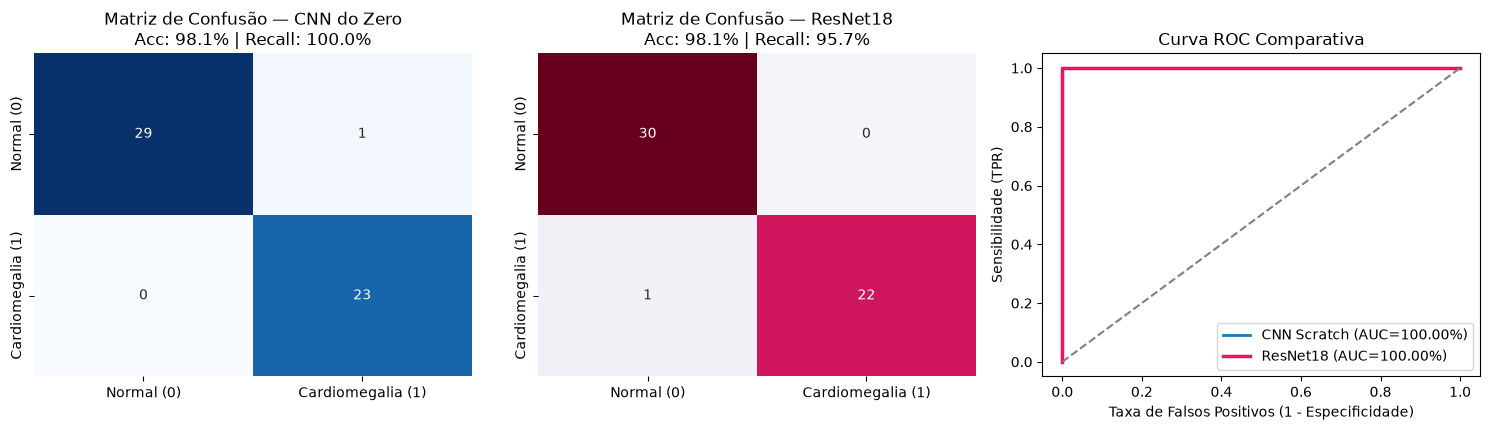

In [6]:
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
cls_names = ["Normal (0)", "Cardiomegalia (1)"]

sns.heatmap(eval_scratch["matriz_confusao"], annot=True, fmt="d", cmap="Blues", xticklabels=cls_names, yticklabels=cls_names, cbar=False, ax=axes[0])
axes[0].set_title(f"Matriz de Confusão — CNN do Zero\nAcc: {eval_scratch['acuracia']*100:.1f}% | Recall: {eval_scratch['recall_sensibilidade']*100:.1f}%")

sns.heatmap(eval_resnet["matriz_confusao"], annot=True, fmt="d", cmap="PuRd", xticklabels=cls_names, yticklabels=cls_names, cbar=False, ax=axes[1])
axes[1].set_title(f"Matriz de Confusão — ResNet18\nAcc: {eval_resnet['acuracia']*100:.1f}% | Recall: {eval_resnet['recall_sensibilidade']*100:.1f}%")

axes[2].plot(eval_scratch["fpr"], eval_scratch["tpr"], label=f"CNN Scratch (AUC={eval_scratch['roc_auc']*100:.2f}%)", lw=2)
axes[2].plot(eval_resnet["fpr"], eval_resnet["tpr"], label=f"ResNet18 (AUC={eval_resnet['roc_auc']*100:.2f}%)", lw=2.5, color="#ED145B")
axes[2].plot([0, 1], [0, 1], "--", color="gray")
axes[2].set_title("Curva ROC Comparativa")
axes[2].set_xlabel("Taxa de Falsos Positivos (1 - Especificidade)")
axes[2].set_ylabel("Sensibilidade (TPR)")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 4. Protótipo Interativo de Inferência e Explicabilidade Clínica no Notebook
A célula abaixo simula o protótipo interativo diretamente no notebook, avaliando exames reais do conjunto de teste e emitindo o laudo clínico automatizado com nível de confiança e recomendação médica.

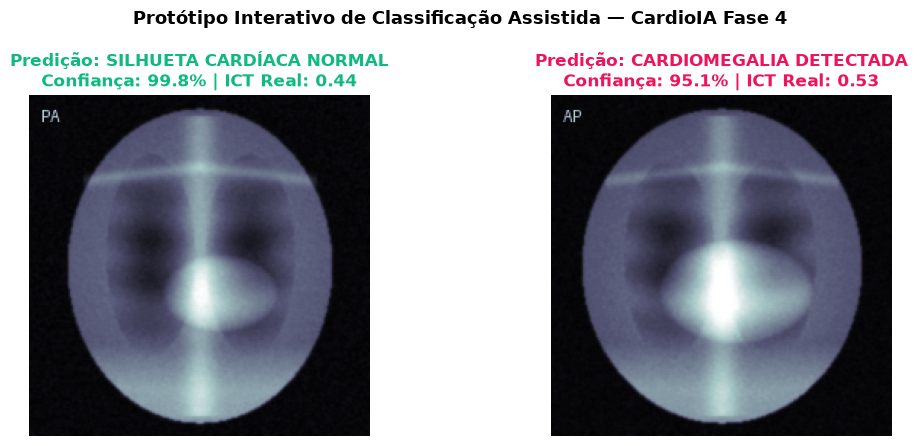

In [7]:
from PIL import Image
from torchvision import transforms
from src.dataset import IMAGENET_MEAN, IMAGENET_STD

infer_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_samples = [
    splits["test"][splits["test"]["label"] == 0].iloc[0],
    splits["test"][splits["test"]["label"] == 1].iloc[0],
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for i, row in enumerate(test_samples):
    pil_im = Image.open(os.path.join(img_dir, row["filename"])).convert("RGB")
    t_in = infer_tf(pil_im).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model_resnet(t_in), dim=1)[0].cpu().numpy()
    prob_cardio = float(probs[1])
    pred_cls = "CARDIOMEGALIA DETECTADA" if prob_cardio >= 0.50 else "SILHUETA CARDÍACA NORMAL"
    conf = prob_cardio * 100 if prob_cardio >= 0.50 else (1 - prob_cardio) * 100

    axes[i].imshow(pil_im.convert("L"), cmap="bone")
    axes[i].set_title(
        f"Predição: {pred_cls}\nConfiança: {conf:.1f}% | ICT Real: {row['ctr_estimated']:.2f}",
        color="#ED145B" if prob_cardio >= 0.50 else "#10B981",
        fontweight="bold",
    )
    axes[i].axis("off")

plt.suptitle("Protótipo Interativo de Classificação Assistida — CardioIA Fase 4", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()